# 05 · Logistic purchase-propensity baseline
**Question:** which customers are most likely to make an eligible purchase within 14 days?
**Y:** `purchase_14d`. **X:** Step 02 pre-send features only (from `feature_schema.csv`); no IDs, treatment, delivery, or outcomes.
**Split:** train CP01–CP05 · validate CP06 (choose C) · test CP07 (untouched until final) · refit CP01–CP07 for Step 07.

## Load data + feature list

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)
from src.common import TABLES, FIGS, MODELS, load_processed
pd.set_option("display.width", 200)
df = load_processed("historical_feature_outcome")
schema = pd.read_csv(TABLES / "feature_schema.csv")
outcomes = set(pd.read_csv(TABLES / "outcome_schema.csv").outcome)
feats = schema[schema.family != "context"]
NUM, CAT = feats[feats.type == "numeric"].feature.tolist(), feats[feats.type == "categorical"].feature.tolist()
X_COLS = NUM + CAT
FORBIDDEN = {"assignment_id", "customer_id", "campaign_id", "send_ts", "outcome_end_ts", "assignment_source", "offer_type", "email_delivered"} | outcomes
assert not set(X_COLS) & FORBIDDEN, set(X_COLS) & FORBIDDEN
print(f"{len(NUM)} numeric + {len(CAT)} categorical = {len(X_COLS)} predictors")

36 numeric + 7 categorical = 43 predictors


## Chronological split

In [2]:
SPLIT = {"train": ["CP01", "CP02", "CP03", "CP04", "CP05"], "valid": ["CP06"], "test": ["CP07"]}
parts = {k: df[df.campaign_id.isin(v)] for k, v in SPLIT.items()}
pd.DataFrame({k: {"rows": len(d), "purchase_rate": round(d.purchase_14d.mean(), 4), "campaigns": ",".join(SPLIT[k])} for k, d in parts.items()}).T

,rows,purchase_rate,campaigns
train,19000,0.1279,"CP01,CP02,CP03,CP04,CP05"
valid,3800,0.1382,CP06
test,3800,0.1318,CP07


## Pipeline

In [3]:
def make_pipe(C):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, l1_ratio=0, solver="lbfgs", max_iter=2000, random_state=42))])

def metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "log_loss": log_loss(y, p),
            "brier": brier_score_loss(y, p), "threshold": thr, "precision": precision_score(y, yh, zero_division=0),
            "recall": recall_score(y, yh), "f1": f1_score(y, yh), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "base_rate": y.mean(), "mean_pred": p.mean()}
Xy = lambda d: (d[X_COLS], d.purchase_14d.values)

## Tune C on CP06 validation

In [4]:
Xtr, ytr = Xy(parts["train"]); Xva, yva = Xy(parts["valid"]); Xte, yte = Xy(parts["test"])
grid = []
for C in [0.01, 0.1, 1, 10]:
    m = make_pipe(C).fit(Xtr, ytr)
    grid.append({"C": C, **metrics(yva, m.predict_proba(Xva)[:, 1]), "n_iter": int(m[-1].n_iter_[0])})
grid = pd.DataFrame(grid)
grid.to_csv(TABLES / "logistic_validation_grid.csv", index=False)
BEST_C = grid.sort_values(["roc_auc", "log_loss"], ascending=[False, True]).C.iloc[0]
print("selected C =", BEST_C, "(max validation ROC-AUC; log loss tiebreak)")
grid[["C", "roc_auc", "pr_auc", "log_loss", "brier", "n_iter"]].round(4)

selected C = 0.01 (max validation ROC-AUC; log loss tiebreak)


,C,roc_auc,pr_auc,log_loss,brier,n_iter
0,0.01,0.6862,0.2652,0.3756,0.1124,44
1,0.10,0.6851,0.2629,0.3755,0.1123,82
2,1.00,0.6837,0.2590,0.3759,0.1124,40
3,10.00,0.6841,0.2601,0.3758,0.1124,44


## Final evaluation on untouched CP07
Threshold 0.50 shown for reference; F1-optimal threshold is chosen on CP06 and then applied to CP07.

In [5]:
model = make_pipe(BEST_C).fit(Xtr, ytr)
p_va, p_te = model.predict_proba(Xva)[:, 1], model.predict_proba(Xte)[:, 1]
pr, rc, th = precision_recall_curve(yva, p_va)
F1_THR = float(th[np.nanargmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))])
res = pd.DataFrame([{"split": "valid_CP06", **metrics(yva, p_va)}, {"split": "test_CP07", **metrics(yte, p_te)},
                    {"split": "valid_CP06_f1thr", **metrics(yva, p_va, F1_THR)}, {"split": "test_CP07_f1thr", **metrics(yte, p_te, F1_THR)}])
res.insert(1, "C", BEST_C)
assert np.isfinite(res[["roc_auc", "pr_auc", "log_loss", "brier"]].values).all()
res.to_csv(TABLES / "logistic_metrics.csv", index=False)
res.round(4).T

,0,1,2,3
split,valid_CP06,test_CP07,valid_CP06_f1thr,test_CP07_f1thr
C,0.01,0.01,0.01,0.01
roc_auc,0.6862,0.6549,0.6862,0.6549
pr_auc,0.2652,0.2306,0.2652,0.2306
log_loss,0.3756,0.3726,0.3756,0.3726
brier,0.1124,0.11,0.1124,0.11
threshold,0.5,0.5,0.1721,0.1721
precision,0.0,0.0,0.2798,0.2357
recall,0.0,0.0,0.4343,0.3852
f1,0.0,0.0,0.3403,0.2924


## Ranking + calibration diagnostics (CP07)

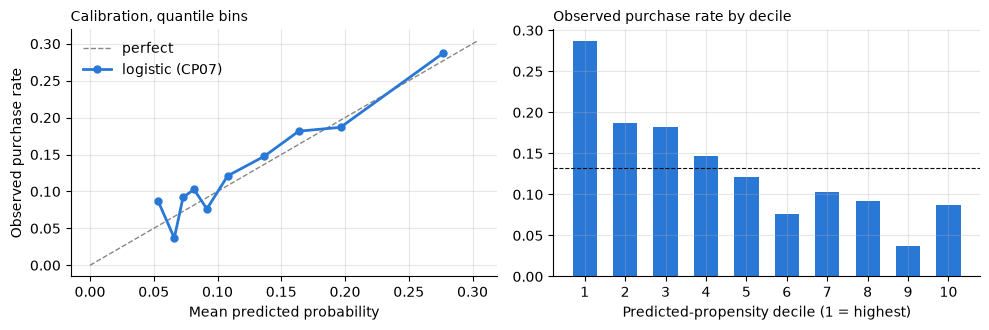

,n,purchase_rate,mean_pred,lift
decile,,,,
1,380,0.287,0.277,2.176
2,380,0.187,0.196,1.417
3,380,0.182,0.164,1.377
4,380,0.147,0.136,1.118
5,380,0.121,0.108,0.918
6,380,0.076,0.092,0.579
7,380,0.103,0.082,0.778
8,380,0.092,0.073,0.699
9,380,0.037,0.066,0.279


In [6]:
te = parts["test"][["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(predicted_purchase_probability=p_te)
te.to_csv(TABLES / "logistic_test_predictions.csv", index=False)
te["decile"] = pd.qcut(te.predicted_purchase_probability.rank(method="first"), 10, labels=range(10, 0, -1))
lift = te.groupby("decile", observed=True).agg(n=("purchase_14d", "size"), purchase_rate=("purchase_14d", "mean"),
                                              mean_pred=("predicted_purchase_probability", "mean")).sort_index(ascending=False)
lift["lift"] = lift.purchase_rate / te.purchase_14d.mean()
lift.to_csv(TABLES / "logistic_test_decile_lift.csv")
fy, fx = calibration_curve(yte, p_te, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot([0, fx.max() * 1.1], [0, fx.max() * 1.1], color="#898781", lw=1, ls="--", label="perfect")
ax[0].plot(fx, fy, marker="o", ms=5, lw=2, color="#2a78d6", label="logistic (CP07)")
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Observed purchase rate"); ax[0].legend(frameon=False)
ax[0].set_title("Calibration, quantile bins", loc="left", fontsize=10)
ax[1].bar(lift.index.astype(str), lift.purchase_rate, color="#2a78d6", width=0.6)
ax[1].axhline(te.purchase_14d.mean(), color="#0b0b0b", lw=0.8, ls="--"); ax[1].set_xlabel("Predicted-propensity decile (1 = highest)")
ax[1].set_title("Observed purchase rate by decile", loc="left", fontsize=10)
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "05_logistic_calibration_lift.png", bbox_inches="tight"); plt.show()
lift.round(3)

## Coefficients (standardized / one-hot scale)

In [7]:
coef = pd.Series(model[-1].coef_[0], index=model[0].get_feature_names_out()).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).round(3).to_frame("coef")

,coef
cat__customer_tier_Standard,-0.611
num__missingindicator_days_since_last_session,-0.145
num__missingindicator_days_since_last_email_click,-0.084
cat__preferred_category_Accessories,-0.071
cat__top_category_viewed_30d_Accessories,-0.068
cat__preferred_category_Footwear,-0.061
num__days_since_last_email_click,-0.060
num__avg_order_value_90d,-0.056
num__prior_offer_redemption_rate,0.047
num__missingindicator_avg_order_value_90d,0.052


## Refit on CP01–CP07 and save artifacts (Step 07 will score July; CP08 not scored here)

In [8]:
Xall, yall = Xy(df)
final = make_pipe(BEST_C).fit(Xall, yall)
joblib.dump(final, MODELS / "logistic_propensity_model.joblib")
spec = {"target": "purchase_14d", "C": BEST_C, "numeric_features": NUM, "categorical_features": CAT,
        "encoded_features": final[0].get_feature_names_out().tolist(), "train_campaigns_final": sorted(df.campaign_id.unique()),
        "split_used_for_evaluation": SPLIT, "f1_threshold_from_valid": F1_THR}
(MODELS / "logistic_model_features.json").write_text(json.dumps(spec, indent=1))
reloaded = joblib.load(MODELS / "logistic_propensity_model.joblib")
assert np.allclose(reloaded.predict_proba(Xte)[:, 1], final.predict_proba(Xte)[:, 1])
print(f"saved + reloaded OK | {len(X_COLS)} raw predictors -> {len(spec['encoded_features'])} encoded")
for p in ["outputs/models/logistic_propensity_model.joblib", "outputs/models/logistic_model_features.json", "outputs/tables/logistic_metrics.csv",
          "outputs/tables/logistic_validation_grid.csv", "outputs/tables/logistic_test_predictions.csv", "outputs/figures/05_logistic_calibration_lift.png"]:
    print(" ", p)

saved + reloaded OK | 43 raw predictors -> 85 encoded
  outputs/models/logistic_propensity_model.joblib
  outputs/models/logistic_model_features.json
  outputs/tables/logistic_metrics.csv
  outputs/tables/logistic_validation_grid.csv
  outputs/tables/logistic_test_predictions.csv
  outputs/figures/05_logistic_calibration_lift.png
